<a href="https://colab.research.google.com/github/GopalKrishna-India/Geospatial/blob/master/Mango_Photo_URL_Review_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mango field-photo URL review (Colab)

This notebook downloads publicly accessible photo URLs from `Photos.xlsx`, removes wrapping quotation marks from URLs, downloads each unique image once, and creates numbered contact sheets for visual review. It does **not** automatically decide whether a photo shows mango. After the contact sheets are reviewed, upload the resulting ZIP back to ChatGPT so the image labels can be checked against the original `S.N` rows.

**Privacy / access note:** images are retrieved from the URLs in your workbook and processed in your Colab runtime. Links that require authentication or have expired will be recorded as failed downloads.

In [5]:
!pip -q install pandas openpyxl pillow requests tqdm

import os, re, io, csv, json, time, zipfile, hashlib, textwrap
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import pandas as pd
import requests
from PIL import Image, ImageOps, ImageDraw, ImageFont
from tqdm.auto import tqdm
from google.colab import files

WORK_DIR = Path('/content/drive/MyDrive/MangoPhotos/mango_photo_review')
IMAGE_DIR = WORK_DIR / 'images'
SHEET_DIR = WORK_DIR / 'contact_sheets'
WORK_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
SHEET_DIR.mkdir(parents=True, exist_ok=True)
print('Setup complete.')

Setup complete.


## 1. Upload the Excel file
Run this cell and select `Photos.xlsx` from your computer. If the workbook has multiple sheets, this notebook uses the first sheet by default.

In [6]:
uploaded = files.upload()
xlsx_files = [name for name in uploaded if name.lower().endswith(('.xlsx', '.xlsm'))]
if not xlsx_files:
    raise ValueError('Please upload an .xlsx or .xlsm workbook.')
INPUT_XLSX = xlsx_files[0]
df = pd.read_excel(INPUT_XLSX, sheet_name=0, dtype=object)
df.columns = [str(c).strip() for c in df.columns]
print('Workbook:', INPUT_XLSX)
print('Rows:', len(df))
print('Columns:', list(df.columns))
display(df.head())

def find_col(columns, candidates):
    norm = {str(c).strip().lower().replace(' ', '').replace('.', ''): c for c in columns}
    for candidate in candidates:
        key = candidate.strip().lower().replace(' ', '').replace('.', '')
        if key in norm:
            return norm[key]
    return None

SN_COL = find_col(df.columns, ['S.N', 'SN', 'S No', 'Serial No', 'Serial Number'])
URL_COL = find_col(df.columns, ['ImageURL', 'Image URL', 'PhotoURL', 'Photo URL', 'URL'])
if URL_COL is None:
    raise ValueError(f'Could not find an ImageURL column. Columns found: {list(df.columns)}')
if SN_COL is None:
    df['_OriginalRow'] = range(2, len(df) + 2)
    SN_COL = '_OriginalRow'

def clean_url(value):
    if pd.isna(value):
        return ''
    s = str(value).strip()
    # Excel cells sometimes contain URLs wrapped in quote characters.
    while len(s) >= 2 and s[0] == s[-1] and s[0] in ('\"', "'"):
        s = s[1:-1].strip()
    if s.lower() in ('', 'nan', 'none', 'null'):
        return ''
    return s

df['_URL_CLEAN'] = df[URL_COL].apply(clean_url)
df['_ReviewRow'] = range(2, len(df) + 2)
url_rows = df[df['_URL_CLEAN'] != ''].copy()
unique_urls = list(dict.fromkeys(url_rows['_URL_CLEAN'].tolist()))
url_to_id = {u: f'IMG{i:05d}' for i, u in enumerate(unique_urls, start=1)}
df['_ImageID'] = df['_URL_CLEAN'].map(url_to_id).fillna('')
print(f'Rows in workbook: {len(df)}')
print(f'Rows with URLs: {len(url_rows)}')
print(f'Unique URLs to download: {len(unique_urls)}')
print(f'Duplicate URL rows: {len(url_rows) - len(unique_urls)}')

Saving Photos.xlsx to Photos (1).xlsx
Workbook: Photos (1).xlsx
Rows: 944
Columns: ['S.N', 'ImageURL']


,S.N,ImageURL
0,1,"""https://firebasestorage.googleapis.com/v0/b/t..."
1,2,"""https://firebasestorage.googleapis.com/v0/b/t..."
2,3,"""https://firebasestorage.googleapis.com/v0/b/t..."
3,4,"""https://firebasestorage.googleapis.com/v0/b/t..."
4,5,"""https://firebasestorage.googleapis.com/v0/b/t..."


Rows in workbook: 944
Rows with URLs: 944
Unique URLs to download: 916
Duplicate URL rows: 28


## 2. Download each unique image
Images are downloaded once per unique URL, even if several spreadsheet rows point to the same URL. Requests use retries and a timeout. This may take some time for hundreds of records.

In [7]:
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

def make_session():
    session = requests.Session()
    retry = Retry(total=2, connect=2, read=2, backoff_factor=0.5, status_forcelist=[429, 500, 502, 503, 504], allowed_methods=['GET'])
    adapter = HTTPAdapter(max_retries=retry, pool_connections=20, pool_maxsize=20)
    session.mount('https://', adapter)
    session.mount('http://', adapter)
    session.headers.update({'User-Agent': 'Mozilla/5.0 (compatible; FieldPhotoReview/1.0)'})
    return session

def safe_ext(content_type, url):
    ct = (content_type or '').lower()
    if 'jpeg' in ct or 'jpg' in ct: return '.jpg'
    if 'png' in ct: return '.png'
    if 'webp' in ct: return '.webp'
    if 'gif' in ct: return '.gif'
    path = url.split('?')[0].lower()
    for ext in ['.jpg', '.jpeg', '.png', '.webp', '.gif']:
        if path.endswith(ext): return '.jpg' if ext == '.jpeg' else ext
    return '.img'

def download_one(item):
    image_id, url = item
    session = make_session()
    try:
        response = session.get(url, timeout=(15, 35), stream=True)
        status_code = response.status_code
        if status_code != 200:
            return {'ImageID': image_id, 'URL': url, 'DownloadStatus': f'HTTP_{status_code}', 'LocalPath': '', 'Bytes': 0, 'Error': f'HTTP {status_code}'}
        content = response.content
        if not content:
            return {'ImageID': image_id, 'URL': url, 'DownloadStatus': 'EMPTY_RESPONSE', 'LocalPath': '', 'Bytes': 0, 'Error': 'Empty response'}
        try:
            im = Image.open(io.BytesIO(content))
            im.verify()
            im = Image.open(io.BytesIO(content))
            width, height = im.size
            fmt = im.format or ''
        except Exception as e:
            return {'ImageID': image_id, 'URL': url, 'DownloadStatus': 'NOT_AN_IMAGE', 'LocalPath': '', 'Bytes': len(content), 'Error': str(e)[:200]}
        ext = safe_ext(response.headers.get('Content-Type'), url)
        if ext == '.img':
            ext = {'JPEG': '.jpg', 'PNG': '.png', 'WEBP': '.webp', 'GIF': '.gif'}.get(fmt.upper(), '.jpg')
        path = IMAGE_DIR / f'{image_id}{ext}'
        path.write_bytes(content)
        return {'ImageID': image_id, 'URL': url, 'DownloadStatus': 'DOWNLOADED', 'LocalPath': str(path), 'Bytes': len(content), 'Width': width, 'Height': height, 'Format': fmt, 'Error': ''}
    except Exception as e:
        return {'ImageID': image_id, 'URL': url, 'DownloadStatus': 'DOWNLOAD_ERROR', 'LocalPath': '', 'Bytes': 0, 'Error': str(e)[:200]}
    finally:
        session.close()

download_results = []
with ThreadPoolExecutor(max_workers=12) as executor:
    futures = [executor.submit(download_one, (url_to_id[url], url)) for url in unique_urls]
    for future in tqdm(as_completed(futures), total=len(futures), desc='Downloading unique photos'):
        download_results.append(future.result())

download_report = pd.DataFrame(download_results).sort_values('ImageID').reset_index(drop=True)
display(download_report['DownloadStatus'].value_counts(dropna=False).rename_axis('Status').to_frame('Count'))
display(download_report[download_report['DownloadStatus'] != 'DOWNLOADED'].head(20))

,Count
Status,
DOWNLOADED,916


,ImageID,URL,DownloadStatus,LocalPath,Bytes,Width,Height,Format,Error


## 3. Build numbered contact sheets
Each tile is labelled with an image ID and the spreadsheet `S.N` value(s). The image ID provides a stable link to the report even if the same URL occurs in multiple rows. The contact sheets are for screening; small or ambiguous photos should be checked at full resolution.

Creating contact sheets:   0%|          | 0/37 [00:00<?, ?it/s]

Created 37 contact sheets for 916 unique images.


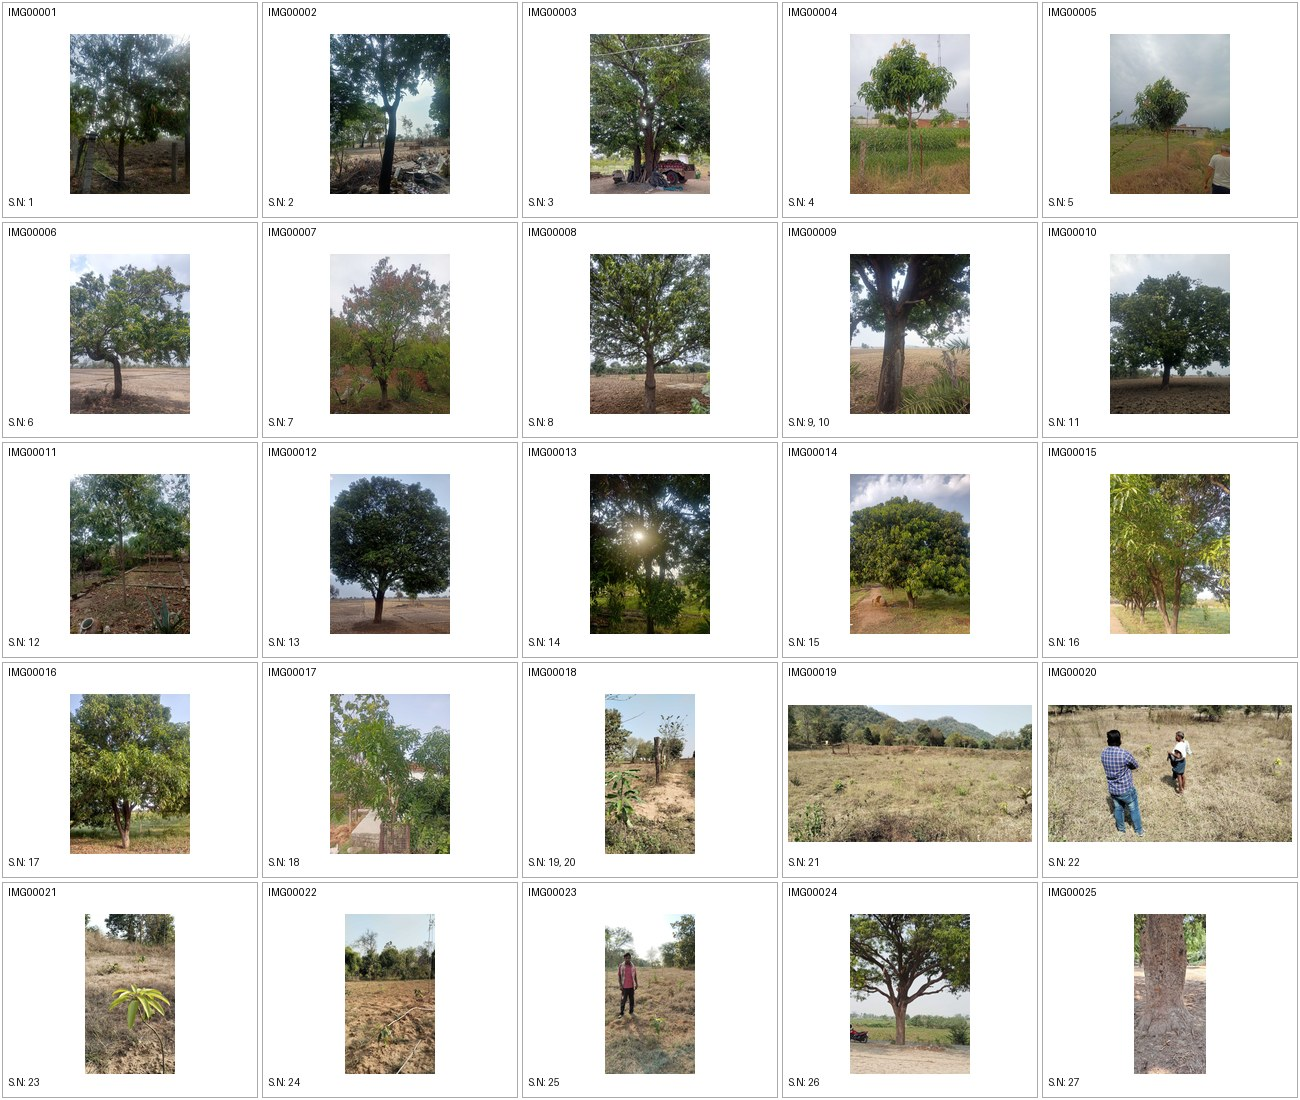

In [8]:
def load_font(size=18, bold=False):
    candidates = ['/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf' if bold else '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf', '/usr/share/fonts/truetype/liberation2/LiberationSans-Bold.ttf' if bold else '/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf']
    for name in candidates:
        if os.path.exists(name):
            try: return ImageFont.truetype(name, size)
            except Exception: pass
    return ImageFont.load_default()

FONT_HEAD = load_font(18, True)
FONT_BODY = load_font(15, False)
TILE_W, TILE_H = 260, 220
COLS, ROWS = 5, 5
PER_SHEET = COLS * ROWS

sn_by_url = {}
for _, row in url_rows.iterrows():
    u = row['_URL_CLEAN']
    sn = str(row[SN_COL]).strip() if pd.notna(row[SN_COL]) else str(row['_ReviewRow'])
    sn_by_url.setdefault(u, []).append(sn)

downloaded = download_report[download_report['DownloadStatus'] == 'DOWNLOADED'].copy()
downloaded['SNs'] = downloaded['URL'].map(lambda u: ', '.join(sn_by_url.get(u, [])))
downloaded = downloaded.sort_values('ImageID').reset_index(drop=True)

def short_sns(s):
    vals = [x.strip() for x in str(s).split(',') if x.strip()]
    if len(vals) <= 3: return ', '.join(vals)
    return ', '.join(vals[:3]) + f' ... (+{len(vals)-3})'

# Rebuild the contact-sheet directory so reruns do not leave stale pages.
for p in SHEET_DIR.glob('*'):
    if p.is_file(): p.unlink()

sheet_index = []
for start in tqdm(range(0, len(downloaded), PER_SHEET), desc='Creating contact sheets'):
    batch = downloaded.iloc[start:start+PER_SHEET]
    page_no = start // PER_SHEET + 1
    canvas = Image.new('RGB', (COLS*TILE_W, ROWS*TILE_H), 'white')
    draw = ImageDraw.Draw(canvas)
    for j, (_, rec) in enumerate(batch.iterrows()):
        x = (j % COLS) * TILE_W
        y = (j // COLS) * TILE_H
        draw.rectangle([x+2, y+2, x+TILE_W-3, y+TILE_H-3], outline=(170,170,170), width=1)
        draw.text((x+8, y+6), str(rec['ImageID']), fill='black', font=FONT_HEAD)
        try:
            im = Image.open(rec['LocalPath']).convert('RGB')
            im.thumbnail((TILE_W-16, 160), Image.Resampling.LANCZOS)
            px = x + (TILE_W-im.width)//2
            py = y + 34 + (160-im.height)//2
            canvas.paste(im, (px, py))
        except Exception:
            draw.text((x+12, y+90), 'Image preview unavailable', fill='red', font=FONT_BODY)
        label = 'S.N: ' + short_sns(rec['SNs'])
        draw.text((x+8, y+196), label[:48], fill=(20,20,20), font=FONT_BODY)
        sheet_index.append({'Sheet': f'contact_{page_no:03d}.jpg', 'ImageID': rec['ImageID'], 'SNs': rec['SNs'], 'URL': rec['URL'], 'LocalPath': rec['LocalPath']})
    sheet_path = SHEET_DIR / f'contact_{page_no:03d}.jpg'
    canvas.save(sheet_path, quality=88, optimize=True)

sheet_index_df = pd.DataFrame(sheet_index)
print(f'Created {len(list(SHEET_DIR.glob("*.jpg")))} contact sheets for {len(downloaded)} unique images.')
if len(list(SHEET_DIR.glob('*.jpg'))) > 0:
    display(Image.open(sorted(SHEET_DIR.glob('*.jpg'))[0]))

## 4. Create the review bundle
The ZIP contains contact sheets, a mapping of image IDs to original URLs and serial numbers, plus a download report. Review labels can later be attached to the `ImageID` or `S.N` values.

In [9]:
review_template = downloaded[['ImageID', 'SNs', 'URL', 'DownloadStatus']].copy()
review_template['ReviewStatus'] = 'UNREVIEWED'
review_template['ReviewNotes'] = ''

# Include failed URLs as well so they can be distinguished from non-mango photos.
failed = download_report[download_report['DownloadStatus'] != 'DOWNLOADED'].copy()
if len(failed):
    failed['SNs'] = failed['URL'].map(lambda u: ', '.join(sn_by_url.get(u, [])))
    failed['ReviewStatus'] = 'UNAVAILABLE'
    failed['ReviewNotes'] = 'Image could not be downloaded; not a species decision.'
    failed = failed[['ImageID', 'SNs', 'URL', 'DownloadStatus', 'ReviewStatus', 'ReviewNotes']]
else:
    failed = pd.DataFrame(columns=['ImageID', 'SNs', 'URL', 'DownloadStatus', 'ReviewStatus', 'ReviewNotes'])
review_template = pd.concat([review_template, failed], ignore_index=True)
review_template = review_template.sort_values('ImageID').reset_index(drop=True)

review_template.to_csv(WORK_DIR / 'review_template.csv', index=False, encoding='utf-8-sig')
download_report.to_csv(WORK_DIR / 'download_report.csv', index=False, encoding='utf-8-sig')
sheet_index_df.to_csv(WORK_DIR / 'contact_sheet_index.csv', index=False, encoding='utf-8-sig')

readme = '''MANGO PHOTO REVIEW BUNDLE\n\nContents:\n- contact_sheets/: numbered JPG contact sheets. Each tile includes ImageID and S.N value(s).\n- review_template.csv: unique URL list, linked S.N values, download status, and blank review fields.\n- download_report.csv: technical download results. A failed download is NOT evidence of non-mango.\n- contact_sheet_index.csv: lookup of each image ID and source URL.\n\nSuggested review labels: MANGO_CONFIRMED, NON_MANGO, UNCERTAIN, TEST_RECORD.\nDo not classify blurry/unavailable photos as non-mango; mark them UNCERTAIN or UNAVAILABLE.\n'''
(WORK_DIR / 'README.txt').write_text(readme, encoding='utf-8')

BUNDLE = Path('/content/mango_photo_review_bundle.zip')
with zipfile.ZipFile(BUNDLE, 'w', zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(WORK_DIR.rglob('*')):
        if not path.is_file() or path == BUNDLE or IMAGE_DIR in path.parents:
            continue
        arcname = str(path.relative_to(WORK_DIR))
        zf.write(path, arcname)

print('Bundle size (MB):', round(BUNDLE.stat().st_size / (1024*1024), 2))
print('Unique URLs attempted:', len(unique_urls))
print('Images downloaded:', int((download_report['DownloadStatus'] == 'DOWNLOADED').sum()))
print('Images unavailable/failed:', int((download_report['DownloadStatus'] != 'DOWNLOADED').sum()))
files.download(str(BUNDLE))

Bundle size (MB): 10.49
Unique URLs attempted: 916
Images downloaded: 916
Images unavailable/failed: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. What to do next
1. Upload `mango_photo_review_bundle.zip` back into the ChatGPT conversation.
2. I can review the numbered contact sheets and return a classification table linked to `ImageID` and `S.N`.
3. For unclear photos, the contact sheet is only a screening view; those images should be checked individually at full resolution.
4. Broken links and inaccessible images must remain `UNAVAILABLE` or `UNCERTAIN`, not be labelled non-mango automatically.